In [125]:
# importig important Libraries in the dataset

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import classification_report,accuracy_score

import warnings

warnings.filterwarnings('ignore')

In [3]:
# Reading the dataset

Loan_data = pd.read_csv('F:\ML Projects\Machine Learning Projects\DataFiles\Loan_status_prediction.csv')

In [4]:
# basic info about the data 

Loan_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             601 non-null    object 
 2   Married            611 non-null    object 
 3   Dependents         599 non-null    object 
 4   Education          614 non-null    object 
 5   Self_Employed      582 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    object 
 12  Loan_Status        614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB


In [5]:
# By seeing above data we can see there are lot of missing values in the data

Loan_data.isnull().sum()

Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64

In [6]:
# There are two options that we can do wwith the  data you can replace the missing values or you can drop the values

# now i will go with 2 option and then i will try with 1st option.

Loan_data = Loan_data.dropna()

In [7]:
# from the above we have dropped all missing values or Nan values.

Loan_data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 480 entries, 1 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            480 non-null    object 
 1   Gender             480 non-null    object 
 2   Married            480 non-null    object 
 3   Dependents         480 non-null    object 
 4   Education          480 non-null    object 
 5   Self_Employed      480 non-null    object 
 6   ApplicantIncome    480 non-null    int64  
 7   CoapplicantIncome  480 non-null    float64
 8   LoanAmount         480 non-null    float64
 9   Loan_Amount_Term   480 non-null    float64
 10  Credit_History     480 non-null    float64
 11  Property_Area      480 non-null    object 
 12  Loan_Status        480 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 52.5+ KB


In [8]:
Loan_data.isnull().sum()

Loan_ID              0
Gender               0
Married              0
Dependents           0
Education            0
Self_Employed        0
ApplicantIncome      0
CoapplicantIncome    0
LoanAmount           0
Loan_Amount_Term     0
Credit_History       0
Property_Area        0
Loan_Status          0
dtype: int64

In [9]:
# Statistical info about the data

Loan_data.describe()

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,480.000000,480.000000,480.000000,480.000000,480.000000
mean,5364.231250,1581.093583,144.735417,342.050000,0.854167
std,5668.251251,2617.692267,80.508164,65.212401,0.353307
min,150.000000,0.000000,9.000000,36.000000,0.000000
25%,2898.750000,0.000000,100.000000,360.000000,1.000000
50%,3859.000000,1084.500000,128.000000,360.000000,1.000000
75%,5852.500000,2253.250000,170.000000,360.000000,1.000000
max,81000.000000,33837.000000,600.000000,480.000000,1.000000


In [12]:
Loan_data.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y
5,LP001011,Male,Yes,2,Graduate,Yes,5417,4196.0,267.0,360.0,1.0,Urban,Y


In [13]:
Loan_data['Gender'].value_counts()

Gender
Male      394
Female     86
Name: count, dtype: int64

In [ ]:
# from the above we can do label encoding.

Loan_data['Gender'] = Loan_data['Gender'].replace({'Male':1,'Female':0}) # Male ==> 1, Female ==> 0
Loan_data['Gender'].value_counts()

Gender
1    394
0     86
Name: count, dtype: int64

In [18]:
# we are going to change the Loan_status coulumn with Yes = 1 and No = 0

Loan_data['Loan_Status'] = Loan_data['Loan_Status'].replace({'Y':1,'N':0})

Loan_data['Loan_Status'].value_counts()

Loan_Status
1    332
0    148
Name: count, dtype: int64

In [19]:
Loan_data.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
1,LP001003,1,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,0
2,LP001005,1,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,1
3,LP001006,1,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,1
4,LP001008,1,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,1
5,LP001011,1,Yes,2,Graduate,Yes,5417,4196.0,267.0,360.0,1.0,Urban,1


In [20]:
Loan_data['Dependents'].value_counts()

Dependents
0     274
2      85
1      80
3+     41
Name: count, dtype: int64

In [24]:
Loan_data['Dependents'] = Loan_data['Dependents'].replace({'3+':4})

In [25]:
Loan_data['Dependents'].value_counts()

Dependents
0    274
2     85
1     80
4     41
Name: count, dtype: int64

In [27]:
Loan_data['Gender'].value_counts()

Gender
0    274
2     85
1     80
4     41
Name: count, dtype: int64

In [28]:
# Reading the dataset

Loan_data1 = pd.read_csv('F:\ML Projects\Machine Learning Projects\DataFiles\Loan_status_prediction.csv')

In [30]:
Loan_data1['Gender'].value_counts()

Gender
Male      489
Female    112
Name: count, dtype: int64

In [31]:
# from the above we can do label encoding.

Loan_data1['Gender'] = Loan_data1['Gender'].replace({'Male':1,'Female':0}) # Male ==> 1, Female ==> 0
Loan_data1['Gender'].value_counts()

Gender
1.0    489
0.0    112
Name: count, dtype: int64

In [34]:
Loan_data.drop('Gender',axis=1)

,Loan_ID,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
1,LP001003,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,0
2,LP001005,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,1
3,LP001006,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,1
4,LP001008,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,1
5,LP001011,Yes,2,Graduate,Yes,5417,4196.0,267.0,360.0,1.0,Urban,1
...,...,...,...,...,...,...,...,...,...,...,...,...
609,LP002978,No,0,Graduate,No,2900,0.0,71.0,360.0,1.0,Rural,1
610,LP002979,Yes,4,Graduate,No,4106,0.0,40.0,180.0,1.0,Rural,1
611,LP002983,Yes,1,Graduate,No,8072,240.0,253.0,360.0,1.0,Urban,1
612,LP002984,Yes,2,Graduate,No,7583,0.0,187.0,360.0,1.0,Urban,1


In [35]:
Loan_data['Gender'] = Loan_data1['Gender']

In [36]:
del Loan_data1

In [37]:
Loan_data.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
1,LP001003,1.0,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,0
2,LP001005,1.0,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,1
3,LP001006,1.0,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,1
4,LP001008,1.0,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,1
5,LP001011,1.0,Yes,2,Graduate,Yes,5417,4196.0,267.0,360.0,1.0,Urban,1


In [41]:
Loan_data['Married'].unique()
print(Loan_data['Education'].unique())
print(Loan_data['Self_Employed'].unique())
print(Loan_data['Property_Area'].unique())

['Graduate' 'Not Graduate']
['No' 'Yes']
['Rural' 'Urban' 'Semiurban']


In [42]:
# There are many columns which needs to do with label endcoding.  Education  Self_Employed Property_Area Married

Loan_data['Married'] = Loan_data['Married'].replace({'Yes':1,'No':0})
Loan_data['Education'] = Loan_data['Education'].replace({'Graduate':1,'Not Graduate':0})
Loan_data['Self_Employed'] = Loan_data['Self_Employed'].replace({'Yes':1,'No':0})
Loan_data['Property_Area'] = Loan_data['Property_Area'].replace({'Rural':0,'Urban':1,'Semiurban':2})

In [43]:
Loan_data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 480 entries, 1 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            480 non-null    object 
 1   Gender             480 non-null    float64
 2   Married            480 non-null    int64  
 3   Dependents         480 non-null    object 
 4   Education          480 non-null    int64  
 5   Self_Employed      480 non-null    int64  
 6   ApplicantIncome    480 non-null    int64  
 7   CoapplicantIncome  480 non-null    float64
 8   LoanAmount         480 non-null    float64
 9   Loan_Amount_Term   480 non-null    float64
 10  Credit_History     480 non-null    float64
 11  Property_Area      480 non-null    int64  
 12  Loan_Status        480 non-null    int64  
dtypes: float64(5), int64(6), object(2)
memory usage: 52.5+ KB


In [44]:
Loan_data['Dependents'].value_counts()

Dependents
0    274
2     85
1     80
4     41
Name: count, dtype: int64

In [52]:
Loan_data['Dependents'] = Loan_data['Dependents'].astype('int64')
Loan_data['Gender'] = Loan_data['Gender'].astype('int64')

In [53]:
Loan_data['Dependents'].dtype

dtype('int64')

In [54]:
Loan_data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 480 entries, 1 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            480 non-null    object 
 1   Gender             480 non-null    int64  
 2   Married            480 non-null    int64  
 3   Dependents         480 non-null    int64  
 4   Education          480 non-null    int64  
 5   Self_Employed      480 non-null    int64  
 6   ApplicantIncome    480 non-null    int64  
 7   CoapplicantIncome  480 non-null    float64
 8   LoanAmount         480 non-null    float64
 9   Loan_Amount_Term   480 non-null    float64
 10  Credit_History     480 non-null    float64
 11  Property_Area      480 non-null    int64  
 12  Loan_Status        480 non-null    int64  
dtypes: float64(4), int64(8), object(1)
memory usage: 52.5+ KB


In [55]:
# Now we will go for the statistical analysis for the above data

Loan_data = Loan_data.drop('Loan_ID',axis=1)

In [56]:
Loan_data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 480 entries, 1 to 613
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Gender             480 non-null    int64  
 1   Married            480 non-null    int64  
 2   Dependents         480 non-null    int64  
 3   Education          480 non-null    int64  
 4   Self_Employed      480 non-null    int64  
 5   ApplicantIncome    480 non-null    int64  
 6   CoapplicantIncome  480 non-null    float64
 7   LoanAmount         480 non-null    float64
 8   Loan_Amount_Term   480 non-null    float64
 9   Credit_History     480 non-null    float64
 10  Property_Area      480 non-null    int64  
 11  Loan_Status        480 non-null    int64  
dtypes: float64(4), int64(8)
memory usage: 48.8 KB


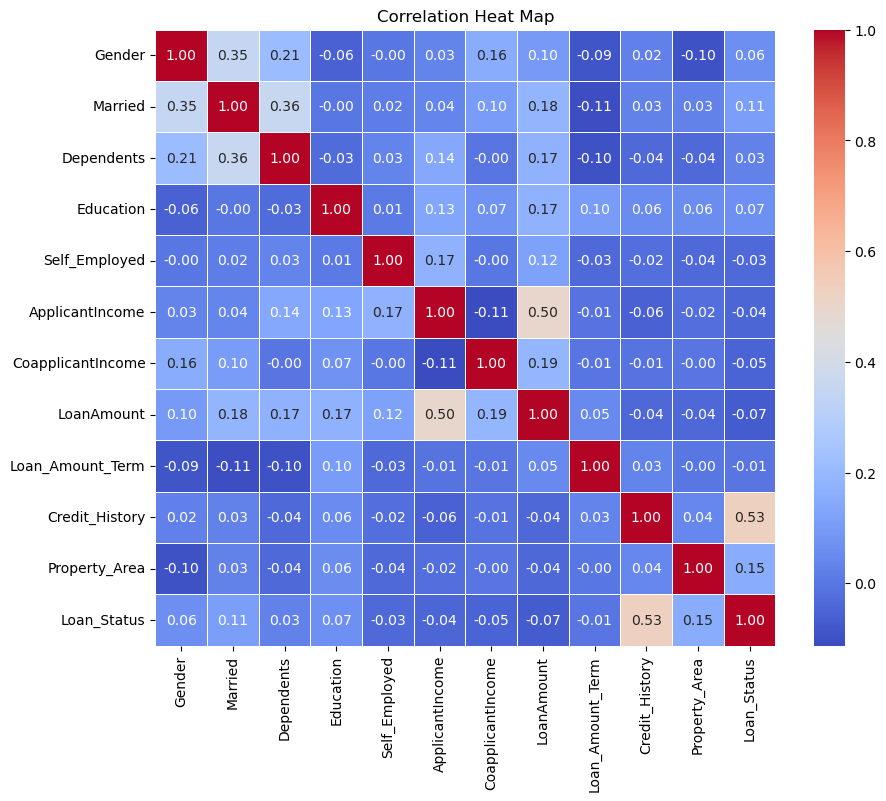

In [60]:
plt.figure(figsize=(10,8))

corr = Loan_data.corr()

sns.heatmap(corr,cmap='coolwarm',annot=True,fmt='.2f',linewidths=0.5)

plt.title('Correlation Heat Map')

plt.show()


In [ ]:
corr = Loan_data.corr()

high_corr_features = corr['Loan_Status'][
    corr['Loan_Status'] >= 0.50
].sort_values(ascending=False)

print(high_corr_features)

Loan_Status       1.00000
Credit_History    0.52939
Name: Loan_Status, dtype: float64


In [65]:
high_corr_features = high_corr_features.drop('Loan_Status')

In [66]:
print(high_corr_features)

Credit_History    0.52939
Name: Loan_Status, dtype: float64


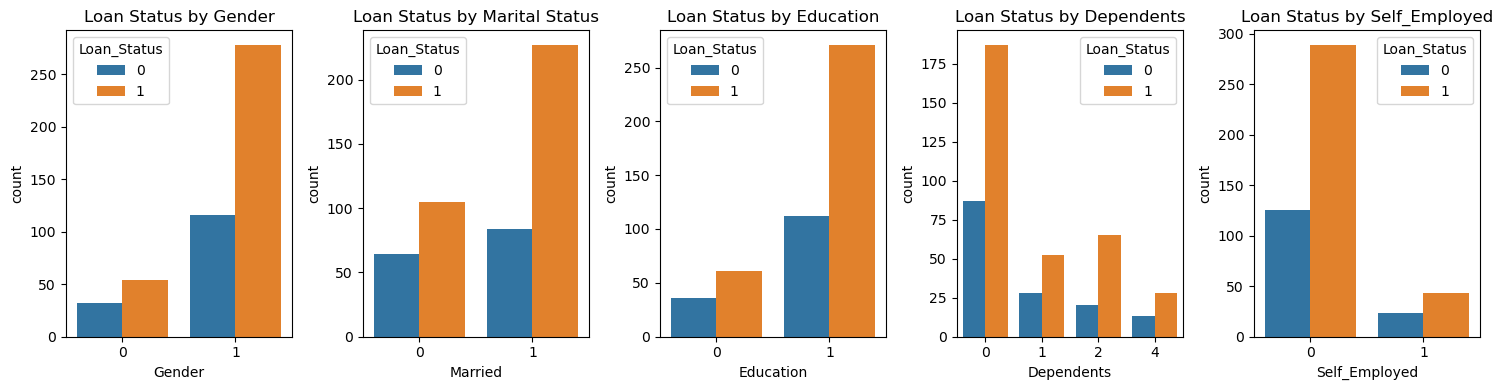

In [86]:
import seaborn as sns
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 5, figsize=(15,4))

sns.countplot(data=Loan_data, x='Gender', hue='Loan_Status', ax=axes[0])
axes[0].set_title('Loan Status by Gender')

sns.countplot(data=Loan_data, x='Married', hue='Loan_Status', ax=axes[1])
axes[1].set_title('Loan Status by Marital Status')

sns.countplot(data=Loan_data, x='Education', hue='Loan_Status', ax=axes[2])
axes[2].set_title('Loan Status by Education')

sns.countplot(data=Loan_data, x='Dependents', hue='Loan_Status', ax=axes[3])
axes[3].set_title('Loan Status by Dependents')

sns.countplot(data=Loan_data, x='Self_Employed', hue='Loan_Status', ax=axes[4])
axes[4].set_title('Loan Status by Self_Employed')

plt.tight_layout()
plt.show()


In [89]:
# Dividing the data set into independet and dependent varibles

X = Loan_data.drop('Loan_Status',axis=1)
y = Loan_data['Loan_Status']

In [113]:
# wanted to apply the standard scalar

from sklearn.preprocessing import StandardScaler

sc = StandardScaler()

X_train = sc.fit(X_train)
X_test = sc.fit_transform(X_test)

In [114]:
# dividing the data set into train test split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42,stratify=y)

In [115]:
X_train.shape,y_train.shape,X_test.shape,y_test.shape

((384, 11), (384,), (96, 11), (96,))

In [116]:
# we are training fitting the model svc

Support_Vector_Classifier = SVC()

In [117]:
Support_Vector_Classifier.fit(X_train,y_train)

SVC()

In [118]:
# Model evaluation on Train data

X_train_prediction = Support_Vector_Classifier.predict(X_train)

accuracy_score_on_x_train = accuracy_score(X_train_prediction,y_train)

print(accuracy_score_on_x_train)

0.703125


In [119]:

X_test_prediction = Support_Vector_Classifier.predict(X_test)

accuracy_score_on_y_test = accuracy_score(X_test_prediction,y_test)

print(accuracy_score_on_y_test)

0.6875


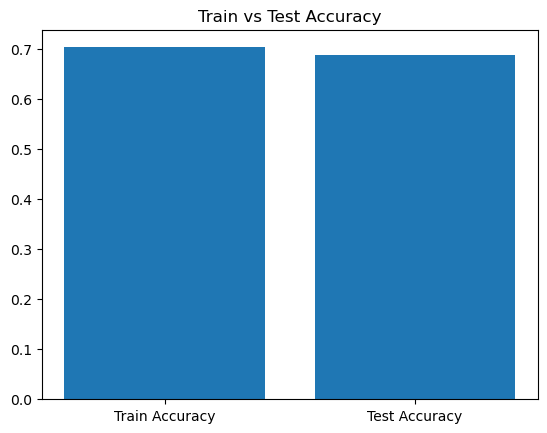

In [120]:
plt.bar(['Train Accuracy', 'Test Accuracy'], [accuracy_score_on_x_train, accuracy_score_on_y_test])
plt.title("Train vs Test Accuracy")
plt.show()


In [ ]:
from sklearn.metrics import confusion_matrix,classification_report,accuracy_score

def evaluvate_model(y_true, y_pred):
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)

    matrix = confusion_matrix(y_true, y_pred)
    report = classification_report(y_true, y_pred)
    acc = accuracy_score(y_true, y_pred)

    return matrix, report, acc

In [122]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier,GradientBoostingClassifier

models = {
    "lr": LogisticRegression(),
    "Svc": SVC(),
    "RF":RandomForestClassifier(),
    "DT": DecisionTreeClassifier(),
    "GBC": GradientBoostingClassifier()
}

In [126]:
model_list = []
acc_score2 = []

for i in range(len(list(models))):
    model=list(models.values())[i]
    model.fit(X_train,y_train)

    #Make Predictions
    y_pred=model.predict(X_test)

    matrix, report, acc =evaluvate_model(y_test.values,y_pred)

    print(list(models.keys())[i])
    model_list.append(list(models.keys())[i])

    print('Model Training Performance')
    print("matrix:",matrix)
    print("report:",report)
    print("acc_score",acc)

    acc_score2.append(acc)
    
    print('='*35)
    print('\n')


lr
Model Training Performance
matrix: [[16 14]
 [ 7 59]]
report:               precision    recall  f1-score   support

           0       0.70      0.53      0.60        30
           1       0.81      0.89      0.85        66

    accuracy                           0.78        96
   macro avg       0.75      0.71      0.73        96
weighted avg       0.77      0.78      0.77        96

acc_score 0.78125


Svc
Model Training Performance
matrix: [[ 0 30]
 [ 0 66]]
report:               precision    recall  f1-score   support

           0       0.00      0.00      0.00        30
           1       0.69      1.00      0.81        66

    accuracy                           0.69        96
   macro avg       0.34      0.50      0.41        96
weighted avg       0.47      0.69      0.56        96

acc_score 0.6875


RF
Model Training Performance
matrix: [[19 11]
 [ 9 57]]
report:               precision    recall  f1-score   support

           0       0.68      0.63      0.66        30
  